In [61]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn.objects as so

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans

##Tp Big Data y Machine Learning
Integrantes:
|Nombre | REG |
|--------|---------|
| Santiago Garcia Ocio | 505230   
| Joaquin  Tarruella                      | 903070
                      
Para el presente trabajo vamos a trabajar con el DataSet de:
 - https://www.kaggle.com/datasets/justinas/nba-players-data/data

Un data set con informacion sobre el desempeño en las temporadas de los jugadores de la NBA (liga profesional EstadoUnidense de baloncesto) desde los años 1996 al 2022.

El dataset describe las estadisticas de los jugadaores basado en la temporada regular, sin contar la fase de eliminatoria (playoffs).

Los años como jugador profesional dento de la NBA se contabilizan como un año de temporada regular, por lo que 1 año de carrera profesional para un jugador es igual a una temporada.

Descripción de las columnas:
| Columna | Descrpicion|
|:---:|:---|
| Nombre| nombre del jugador.|
| Equipo| Equipo para el cual el jugador jugo durante la temporada. Si cambio de equipo a durante la temporada el equipo será el equipo con quien terminó|
| Edad| Edad del jugador|
| Altura | ALtura del jugador en centimetros|
| Peso | Peso del jugador en kilogramos|
| Universidad | Nombre de la universidad a la que asistio el jugador|
| Pais | Pais de nacimiento del jugador (no necesariamene su nacionalidad)|
| Año draft | Año en el que el jugador fue seleccionado para la NBA.|
| Ronda draft | Ronda del draft en la que el jugador fue seleccionado.|
| Numero draft| El numero en el que el jugador fue seleecionado en su ronda de draft.|
| Partidos | Cantidad de partidos jugados en la temporada|
| Puntos | media de puntos realizados por partido en la temporada|
| Rebores | media de rebotes por partido en la temporada|
| Asistencias | media de asistencias realizadas por partido en la temporada|
| Influencia neta | Diferencia de puntos totales del equipo por cada 100 poseciones mientras el jugador estaba en la cancha|
| Rebotes ofs pct | Porcentaje de rebotes ofensivos que el jugador gano mientras estaba en la cancha|
| Rebotes def pct | Porcentaje de rebotes defensivos que el jugador gano mientras estaba en la cancha|
| Uso pct |  porcentaje de jugadas del equipo que son finalizadas por el jugador específico mientras está en cancha. $$\\$$ Menos de 0.15 : jugador defensivo o pasivo en ataque. $$\\$$<br>De 0.20 a 0.24 : Nivel promedio<br>De 0.25 a 0.29 : Segunda o tercera posicion ofensiva del equipo<br>Mas de 0.30 : Superestrella o 'jugador franquicia' $$\frac{\text{(Lanzamientos a canasta + lanzamientos tiro libre + balones perdidos)} * \text{Minutos del equipo}}{\text{Lanzamientos a canasta + lanzamientos tiro libre + balones perdidos}*\text{Minutos del Jugador}}$$ |
| Aciertor pct | Eficiencia de tiro al cesto. $$\frac{\text{Puntos}}{2*(\text{Intentos de Tiro de campo} + 0.44* \text{Intentos de Tiro Libre}})$$|
|asistencias_pct | Porcentaje de los puntos de campo del equip en los que el jugador asistio mientras estaba en la cancha|
|temporada|La temporada de la NBA|


#1. Configuración de Entorno y Lectura de Datos


In [62]:
path='https://drive.google.com/uc?export=download&id=16u_Kd7LaFIyb5SxVhsMx7npzU1sQbLFg'

df = pd.read_csv(path,index_col=0)

#Renombramos las columnas a castellano
renombre_columnas = {'player_name':'jugador', 'team_abbreviation':'equipo', 'age':'edad', 'player_height':'altura',
       'player_weight':'peso', 'college':'universidad', 'country':'pais', 'draft_year':'año_draft', 'draft_round':'ronda_draft',
       'draft_number':'numero_draft', 'gp':'partidos', 'pts':'puntos', 'reb':'rebotes', 'ast':'asistencias', 'net_rating':'influencia_neta', 'oreb_pct':'rebotes_ofs_pct',
       'dreb_pct':'rebotes_def_pct', 'usg_pct':'uso_pct', 'ts_pct':'aciertos_pct', 'ast_pct':'asistencias_pct', 'season':'temporada'
}

df.columns = df.columns.map(renombre_columnas)

In [63]:
df.shape

(12844, 21)

Tenemos 12844 filas y 21 columnas en nuestro dataframe

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12844 entries, 0 to 12843
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   jugador          12844 non-null  object 
 1   equipo           12844 non-null  object 
 2   edad             12844 non-null  float64
 3   altura           12844 non-null  float64
 4   peso             12844 non-null  float64
 5   universidad      10990 non-null  object 
 6   pais             12844 non-null  object 
 7   año_draft        12844 non-null  object 
 8   ronda_draft      12844 non-null  object 
 9   numero_draft     12844 non-null  object 
 10  partidos         12844 non-null  int64  
 11  puntos           12844 non-null  float64
 12  rebotes          12844 non-null  float64
 13  asistencias      12844 non-null  float64
 14  influencia_neta  12844 non-null  float64
 15  rebotes_ofs_pct  12844 non-null  float64
 16  rebotes_def_pct  12844 non-null  float64
 17  uso_pct          

Vemos que en general las columnas no tienen datos faltantes. La única que si tiene es universidad. Explorando la meta-data vemos que los datos nulos representan a atletas que no fueron a la universidad.

A su vez las columnas 'año_draft', 'ronda_draft', 'numero_draft' y 'temporada' fueron importada como String, a pesar de ser Numericas.

In [65]:
df['año_draft'].unique()

array(['1996', '1994', '1993', '1989', '1995', '1985', '1988', '1991',
       '1986', '1990', '1984', '1987', '1982', '1992', 'Undrafted',
       '1983', '1981', '1978', '1979', '1980', '1976', '1997', '1998',
       '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006',
       '2007', '2008', '2009', '2010', '2011', '1963', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021',
       '2022'], dtype=object)

Vemos que el valor culpable es 'Undrafted' que representa a los jugadores que no fueron seleccionados en el draft y en cambio ingresaron a la NBA por otros medios.

In [66]:
df['año_draft'] = pd.to_numeric(df['año_draft'], errors='coerce').astype('Int64')
df['ronda_draft'] = pd.to_numeric(df['ronda_draft'], errors='coerce').astype('Int64')
df['numero_draft'] = pd.to_numeric(df['numero_draft'], errors='coerce').astype('Int64')

Pasamos las columnas a numéricas, los jugadores 'undrafted' pasar a NaN. Esto nos permitira una mejor manipulación de las columnas a la hora de explorarlas.

In [67]:
df['temporada'].unique()

array(['1996-97', '1997-98', '1998-99', '1999-00', '2000-01', '2001-02',
       '2002-03', '2003-04', '2004-05', '2005-06', '2006-07', '2007-08',
       '2008-09', '2009-10', '2010-11', '2011-12', '2012-13', '2013-14',
       '2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20',
       '2020-21', '2021-22', '2022-23'], dtype=object)

La columna 'temporada' por su parte fue tomada como string dado a su formate. La pasamos a numérica separando por el '-' y quedandonos solamente con el primer año

In [68]:
df['temporada'] = df['temporada'].str.split('-',expand=True).loc[:,0].astype('Int64')

In [69]:
df.head()

,jugador,equipo,edad,altura,peso,universidad,pais,año_draft,ronda_draft,numero_draft,...,puntos,rebotes,asistencias,influencia_neta,rebotes_ofs_pct,rebotes_def_pct,uso_pct,aciertos_pct,asistencias_pct,temporada
0,Randy Livingston,HOU,22.0,193.04,94.800728,Louisiana State,USA,1996,2,42,...,3.9,1.5,2.4,0.3,0.042,0.071,0.169,0.487,0.248,1996
1,Gaylon Nickerson,WAS,28.0,190.50,86.182480,Northwestern Oklahoma,USA,1994,2,34,...,3.8,1.3,0.3,8.9,0.030,0.111,0.174,0.497,0.043,1996
2,George Lynch,VAN,26.0,203.20,103.418976,North Carolina,USA,1993,1,12,...,8.3,6.4,1.9,-8.2,0.106,0.185,0.175,0.512,0.125,1996
3,George McCloud,LAL,30.0,203.20,102.058200,Florida State,USA,1989,1,7,...,10.2,2.8,1.7,-2.7,0.027,0.111,0.206,0.527,0.125,1996
4,George Zidek,DEN,23.0,213.36,119.748288,UCLA,USA,1995,1,22,...,2.8,1.7,0.3,-14.1,0.102,0.169,0.195,0.500,0.064,1996


In [70]:
df.tail()

,jugador,equipo,edad,altura,peso,universidad,pais,año_draft,ronda_draft,numero_draft,...,puntos,rebotes,asistencias,influencia_neta,rebotes_ofs_pct,rebotes_def_pct,uso_pct,aciertos_pct,asistencias_pct,temporada
12839,Joel Embiid,PHI,29.0,213.36,127.005760,Kansas,Cameroon,2014,1,3,...,33.1,10.2,4.2,8.8,0.057,0.243,0.370,0.655,0.233,2022
12840,John Butler Jr.,POR,20.0,213.36,86.182480,Florida State,USA,<NA>,<NA>,<NA>,...,2.4,0.9,0.6,-16.1,0.012,0.065,0.102,0.411,0.066,2022
12841,John Collins,ATL,25.0,205.74,102.511792,Wake Forest,USA,2017,1,19,...,13.1,6.5,1.2,-0.2,0.035,0.180,0.168,0.593,0.052,2022
12842,Jericho Sims,NYK,24.0,208.28,113.398000,Texas,USA,2021,2,58,...,3.4,4.7,0.5,-6.7,0.117,0.175,0.074,0.780,0.044,2022
12843,JaMychal Green,GSW,33.0,205.74,102.965384,Alabama,USA,<NA>,<NA>,<NA>,...,6.4,3.6,0.9,-8.2,0.087,0.164,0.169,0.650,0.094,2022


Todo parece estar en orden. Podemos proceder a un analizis inicial de los datos

#Análisis Exploratorio de Datos (AED)

In [71]:
df.describe()

,edad,altura,peso,año_draft,ronda_draft,numero_draft,partidos,puntos,rebotes,asistencias,influencia_neta,rebotes_ofs_pct,rebotes_def_pct,uso_pct,aciertos_pct,asistencias_pct,temporada
count,12844.000000,12844.000000,12844.000000,10486.0,10433.0,10430.0,12844.000000,12844.000000,12844.000000,12844.000000,12844.000000,12844.000000,12844.000000,12844.000000,12844.000000,12844.000000,12844.0
mean,27.045313,200.555097,100.263279,2004.030422,1.303939,21.888878,51.154158,8.212582,3.558486,1.824681,-2.226339,0.054073,0.140646,0.184641,0.513138,0.131595,2009.609467
std,4.339211,9.111090,12.426628,9.008105,0.505454,16.051385,25.084904,6.016573,2.477885,1.800840,12.665124,0.043335,0.062513,0.053545,0.101724,0.094172,7.879836
min,18.000000,160.020000,60.327736,1963.0,0.0,0.0,1.000000,0.000000,0.000000,0.000000,-250.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1996.0
25%,24.000000,193.040000,90.718400,1997.0,1.0,9.0,31.000000,3.600000,1.800000,0.600000,-6.400000,0.021000,0.096000,0.149000,0.482000,0.066000,2003.0
50%,26.000000,200.660000,99.790240,2004.0,1.0,19.0,57.000000,6.700000,3.000000,1.200000,-1.300000,0.040000,0.130500,0.181000,0.525000,0.103000,2010.0
75%,30.000000,208.280000,108.862080,2011.0,2.0,33.0,73.000000,11.500000,4.700000,2.400000,3.200000,0.083000,0.179000,0.217000,0.563000,0.179000,2017.0
max,44.000000,231.140000,163.293120,2022.0,8.0,165.0,85.000000,36.100000,16.300000,11.700000,300.000000,1.000000,1.000000,1.000000,1.500000,1.000000,2022.0


Vemos que el jugador promedio de la NBA es una persona de 27 años, de 2 metros y 100 kg. Fue seleccionado entre la primera y la segunda ronda del draft y jugo 51 partidas en la temporada.

Se observa que una temporada regular cuenta con 85 partidos totales de los cuales el 75% de los jugadores no logra completar mas de 73 partidos totales y un 25% de los jugadores no logra completar media temporada. Esto Muestra el alto grado de competividad y exigencia que tiene jugar en la NBA. Los factores se pueden deber a lesiones, peridos cortos de contrato o factores estrategicos de cada equipo dependiendo su situacion particular.

Que la media de ronda-draft sea 1.3 nos indica que la majoria de los jugadores seleccionados luego de las primeras 2 rondas tienen carreras cortas.

Las medias de métricas de desempeño son bajas, notamos que la influencia_neta media es negativa. Esto se explica por la cantidad de jugadores de reserva que tienen los equipos. Aquellos jugadores que ingresan cuando el partido esta definido, o para que las 'super-estrellas' descansen.

Notamos que puntos, rebotes, y asistencias tienen comportamientos similares. El quartil 3 es aproximadamente 4 veces mayor que el quartil 1. Los jugadores 'estrella' en esas posiciones tienen un rendimiento 4 veces mayor a los otros jugadores.

In [72]:
df.describe(include='O')

,jugador,equipo,universidad,pais
count,12844,12844,10990,12844
unique,2551,36,356,82
top,Vince Carter,CLE,Kentucky,USA
freq,22,450,447,10721


Analizando las variables categoricas vemos, sin mucha sorpresa, que USA es el pais mas representado en la NBA, que el equipo Cleveland fue el que mas jugadores tuvo durante las temporadas analizadas y que la universidad de Kentucky parece ser la mayor productora de futuros jugadores de Basket de estados unidos, al menos en terminos netos.

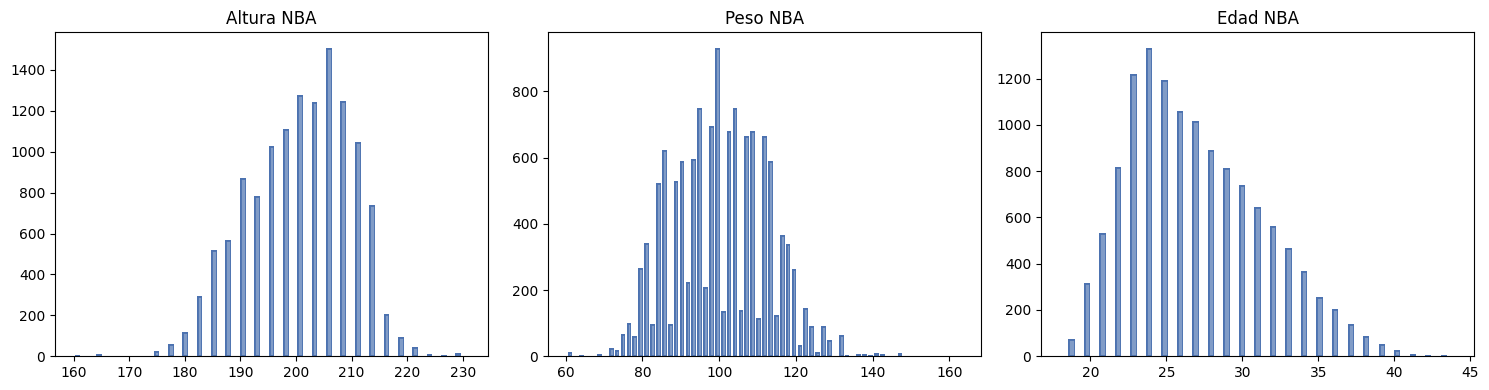

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, columna in zip(axes, ["altura", "peso", "edad"]):
    (
        so.Plot(df, x=columna)
        .add(so.Bar(), so.Hist())
        .label(title=f'{columna.capitalize()} NBA', x='')
    ).on(ax).plot()

plt.tight_layout()
plt.show()

Vemos que el peso se encuentra distribuidos de una manera bastante normal. Las colas son casi inexistentes y la concentracion e nla media de 100 es muy elevada. A diferencia de altura que es algo inmutable existe un rango de peso que el consenso medico indica es el ideal para un atleta de alto rendimiento; en un deporte tan fisico como el baloncesto.

El gráfico de las edades, con alto sesgo positivo, evidencia la dificultad de sostener las demandas de ser jugador profesional con el paso del tiempo. Entre el empeoramiento, en terminos de atletas de alto rendimiento, del desempeño fisico del cuerpo natural con la edad se suma la llegada al mercado de nuevos talentos. Por lo tanto solamente los jugadores mas exepcionales logran mantenerse en la liga profesional año tras año.

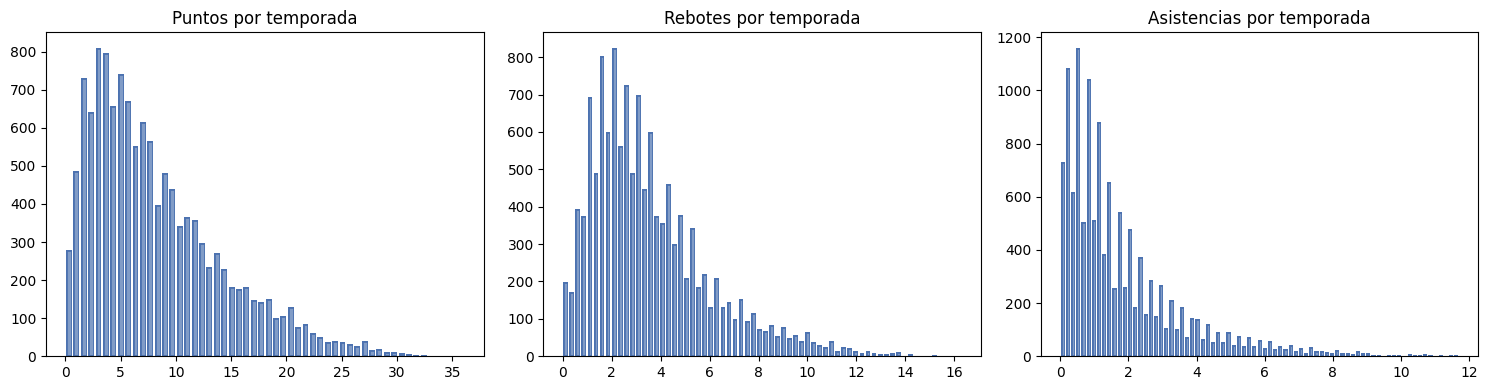

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, columna in zip(axes, ["puntos", "rebotes", "asistencias"]):
    (
        so.Plot(df, x=columna)
        .add(so.Bar(), so.Hist())
        .label(title=f'{columna.capitalize()} por temporada', x='')
    ).on(ax).plot()

plt.tight_layout()
plt.show()

Putos: Se puede ver que la media de los jugadores promedia 8,21 puntos por partidos por temporada. Solo un 25% de todos los jugadores logran promedidar mas de dos digitos de putos por partido en un temporada, por lo que se puede interpretar como jugadores altamente ofencivos, y solo el 5% de todos los jugadores logran alcanzar promediar 20 o mas puntos. Estos ultimos serian las 'superestrellas', los jugadores deciscivos, al menos ofensivamente, de un equipo.

Rebotes: media de 3.56 rebotes por partido. Esta estadicica depende mucho de la altura y posicion del jugador.

Asistencias: media de 1.82 asistencias por partido. Tambien depende mucho de la altura y posicion del jugador

Las tres presentan distribuciones alto sesgo positivo


In [75]:
df["decada"] = (df["temporada"] // 10) * 10

In [76]:
media_decada = df.groupby("decada")[["puntos", "rebotes", "asistencias"]].mean()

Text(0.5, 1.0, 'Cambio en los puntos, rebotes, y asistencias por Temporada de los Jugadores a lo largo del tiempo')

<Figure size 1200x600 with 0 Axes>

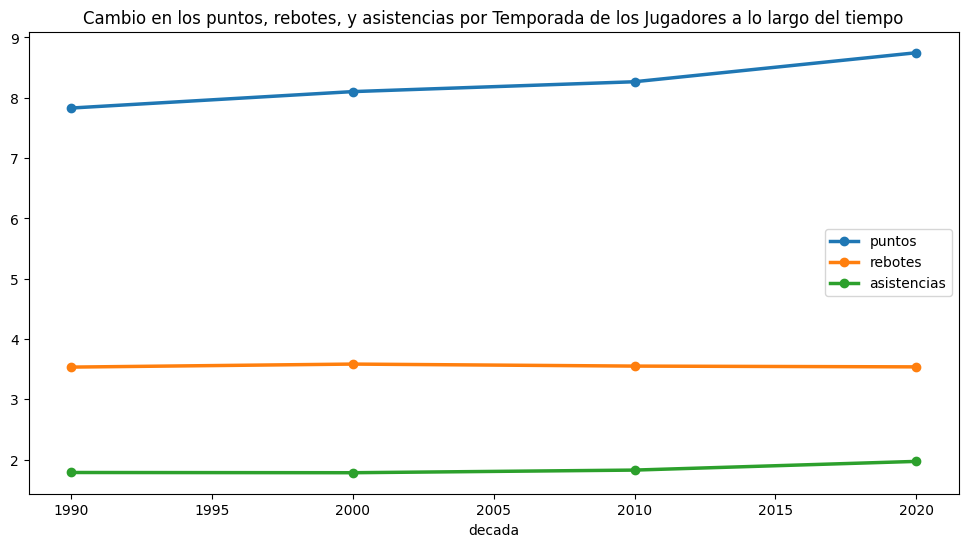

In [77]:
plt.figure(figsize=(12, 6))
ax = media_decada.plot(marker="o", linewidth=2.5, figsize=(12, 6))
plt.title('Cambio en los puntos, rebotes, y asistencias por Temporada de los Jugadores a lo largo del tiempo')

Vemos que las tres metricas se mantienen estables con el paso del tiempo. Los puntos por partidos tuvieron un leve incremento, asi como tambien las asistencias.

In [78]:
colores = [
    line.get_color() for line in ax.get_lines()
]
for i, col in enumerate(["puntos", "rebotes", "asistencias"]):
  mejor_decada = media_decada[col].idxmax()
  valor_maximo = media_decada.loc[mejor_decada, col]

In [79]:
df["origen"] = df["pais"].apply(
    lambda x: (
        "USA" if str(x).strip().upper() in ["USA"] else "No USA"
    )
)

In [80]:
stats_origen = (
    df.groupby(["temporada", "origen"])[["puntos", "rebotes", "asistencias"]]
    .mean()
    .unstack("origen")
)

Text(0.5, 1.0, 'Comparación de jugadores Internacionales vs USA a lo largo del tiempo')

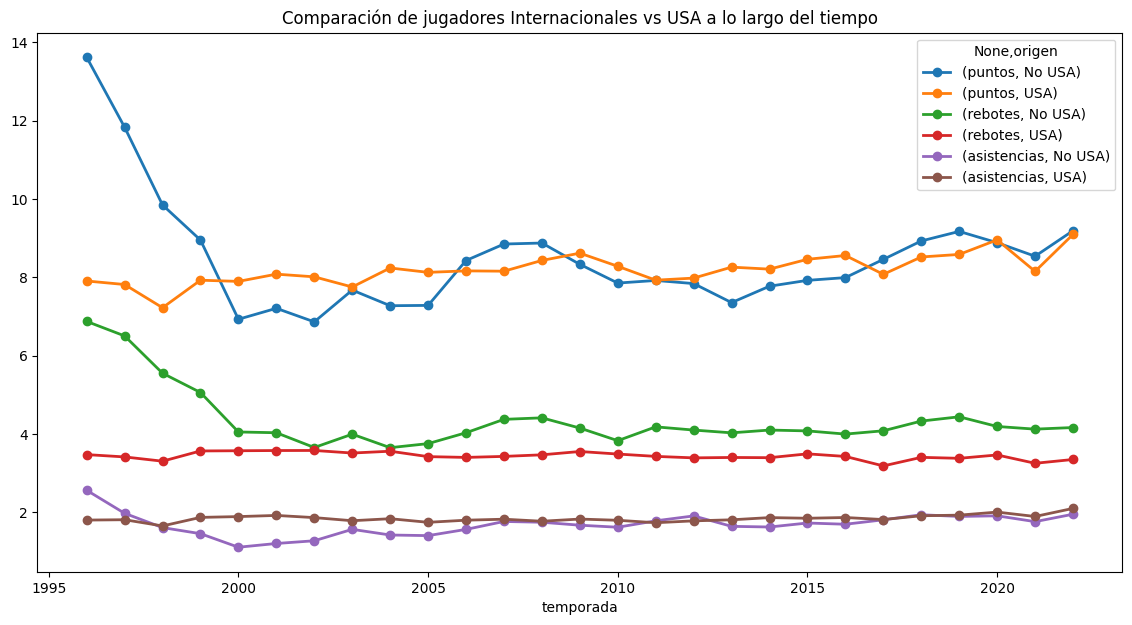

In [81]:
plt.figure(figsize=(14, 7))
stats_origen.plot(marker="o", linewidth=2, ax=plt.gca())
plt.title('Comparación de jugadores Internacionales vs USA a lo largo del tiempo')

Vemos unas relaciones interesantes entre los jugadores Internacionales y los EstadoUnidenses a lo largo del tiempo.

En la decada de los '90 los jugadores importados eran considerablemente mas efectivos que los USA tanto en puntos como en rebotes. Sin embargo a partir de los 2000 los valores de las metricas se acercaron. Rebotes es la única donde, consistentemente, los jugadores Internacionales superan a los Americanos.

Estos comportamientos se podrian explicar por dos razones:
- La dominancia inical de los Internacionles por la baja representatividad. En los '90 la cantidad de jugadores importados era mucho menor. Por lo tanto solo se importaban a los mejores jugadores. Con el paso del tiempo se importaron mas jugadores entonces las medias de ambos grupos convergieron.
- La diferencia, leve pero persistente, en la metrica de Rebotes puede ser atribuida a una diferencia de estilos de Basket en America y el resto del mundo.

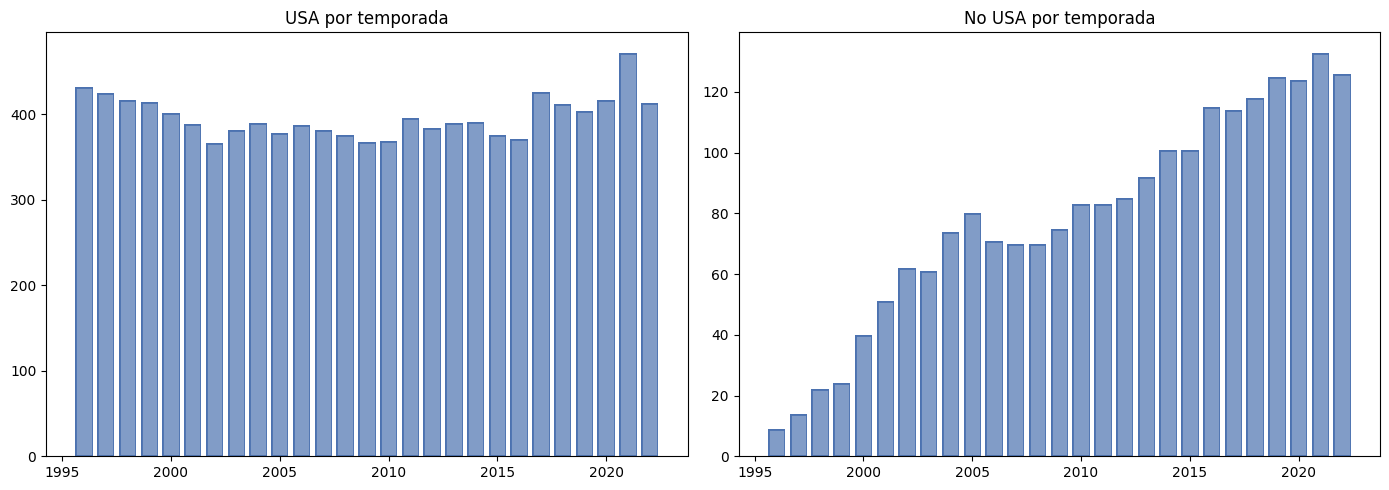

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, origen in zip(axes, ["USA", "No USA"]):
    datos = df[df["origen"] == origen]["temporada"].value_counts().reset_index()

    (
        so.Plot(datos, x="temporada", y="count")
        .add(so.Bar())
        .label(
            title=f"{origen} por temporada",
            x="",
            y=""
        )
    ).on(ax).plot()

plt.tight_layout()
plt.show()

Podemos ver en estos gráficos como, efectivamente, el numero de jugadores internaciones aumento sustancialemnte con el paso del tiempo.

In [83]:
continentes = {
    # América del Norte
    "Canada": "América del Norte",    "Mexico": "América del Norte",    "USA": "América del Norte",

    # América Central
    "Belize": "América Central",    "Panama": "América Central",

    # Caribe
    "Bahamas": "Caribe",    "Dominican Republic": "Caribe",    "Haiti": "Caribe",    "Jamaica": "Caribe",    "Puerto Rico": "Caribe",    "Saint Lucia": "Caribe",
    "St. Vincent & Grenadines": "Caribe",    "Trinidad and Tobago": "Caribe",    "U.S. Virgin Islands": "Caribe",    "US Virgin Islands": "Caribe",

    # América del Sur
    "Argentina": "América del Sur",    "Brazil": "América del Sur",    "Colombia": "América del Sur",    "Uruguay": "América del Sur",    "Venezuela": "América del Sur",

    # Europa
    "Austria": "Europa",    "Bosnia": "Europa",    "Bosnia & Herzegovina": "Europa",    "Bosnia and Herzegovina": "Europa",    "Croatia": "Europa",    "Czech Republic": "Europa",
    "Denmark": "Europa",    "England": "Europa",    "Finland": "Europa",    "France": "Europa",    "Georgia": "Europa",    "Germany": "Europa",    "Great Britain": "Europa",    "Greece": "Europa",
    "Ireland": "Europa",    "Italy": "Europa",    "Latvia": "Europa",    "Lithuania": "Europa",    "Macedonia": "Europa",    "Montenegro": "Europa",    "Netherlands": "Europa",    "Poland": "Europa",
    "Portugal": "Europa",    "Russia": "Europa",    "Scotland": "Europa",    "Serbia": "Europa",    "Serbia and Montenegro": "Europa",    "Slovenia": "Europa",    "Spain": "Europa",
    "Sweden": "Europa",    "Switzerland": "Europa",    "Turkey": "Europa",   "Ukraine": "Europa",    "United Kingdom": "Europa",    "USSR": "Europa",    "Yugoslavia": "Europa",

    # Asia
    "China": "Asia",    "Iran": "Asia",    "Israel": "Asia",    "Japan": "Asia",    "South Korea": "Asia",

    # África
    "Angola": "África",    "Cabo Verde": "África",    "Cameroon": "África",    "Congo": "África",    "DRC": "África",    "Democratic Republic of the Congo": "África",    "Republic of the Congo": "África",    "Egypt": "África",    "Gabon": "África",
    "Ghana": "África",    "Guinea": "África",    "Mali": "África",    "Nigeria": "África",    "Senegal": "África",    "South Sudan": "África",    "Sudan": "África",    "Sudan (UK)": "África",    "Tanzania": "África",    "Tunisia": "África",

    # Oceanía
    "Australia": "Oceanía",    "New Zealand": "Oceanía"
}
df['continentes'] = df['pais'].map(continentes)

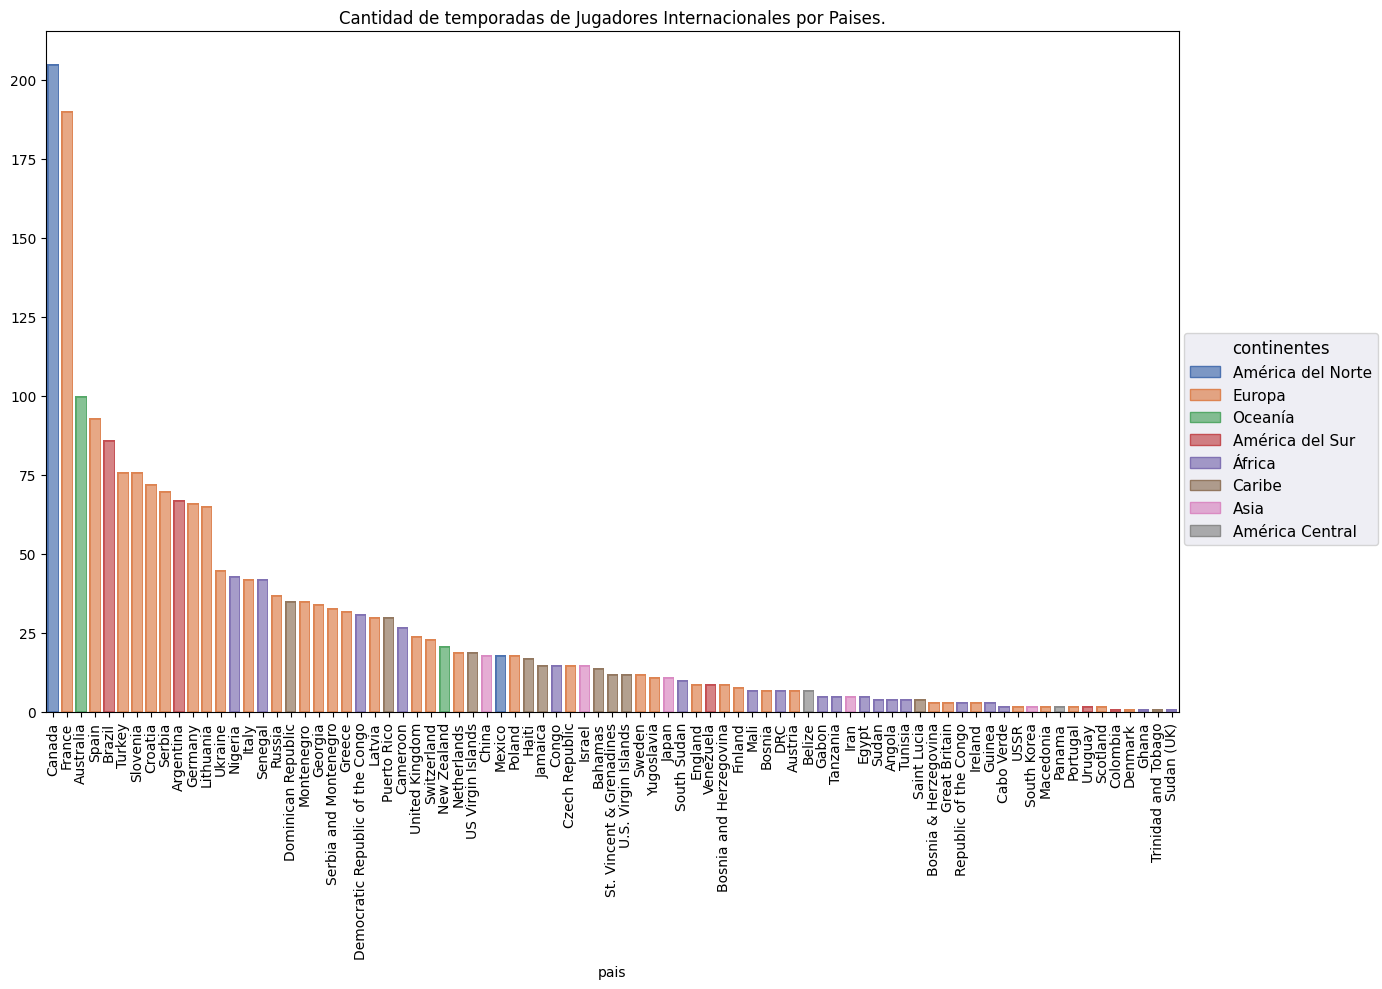

In [84]:
fig, ax = plt.subplots(figsize=(12, 10))
(
    so.Plot(
        df[df["pais"] != "USA"][["pais",'continentes']].value_counts().reset_index(),
        x='pais',
        y='count',
        color='continentes'
    )
    .add(so.Bar())
    .label(title='Cantidad de temporadas de Jugadores Internacionales por Paises.',
           y='')
).on(ax).plot()

ax.tick_params(axis="x", labelrotation=90)
plt.tight_layout()
plt.show()

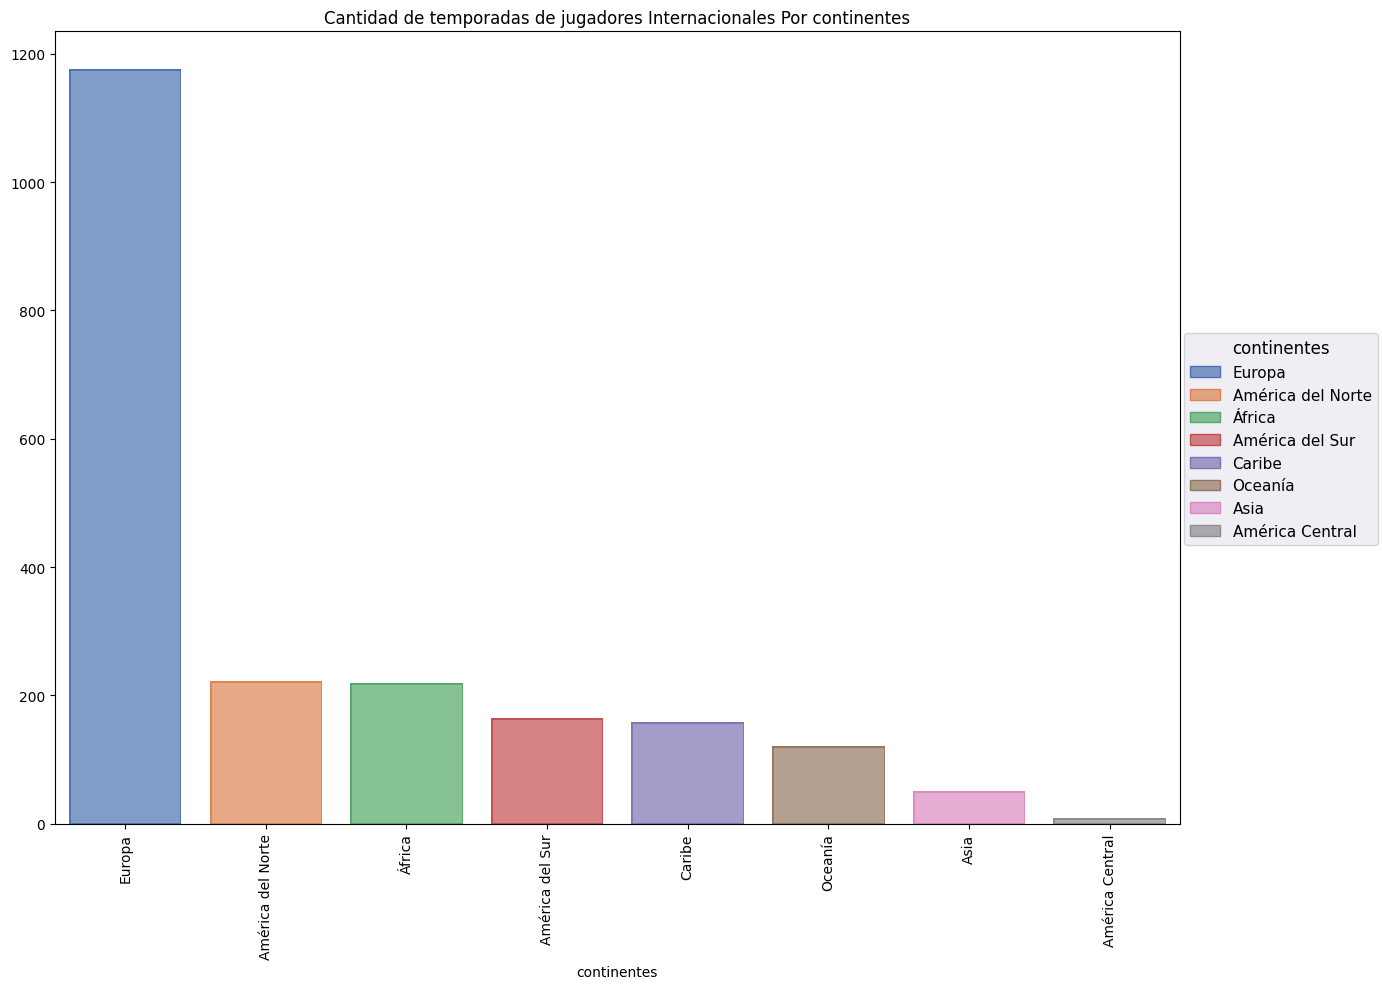

In [85]:
fig, ax = plt.subplots(figsize=(12, 10))
(
    so.Plot(
        df[df["pais"] != "USA"]['continentes'].value_counts().reset_index(),
        x='continentes',
        y='count',
        color='continentes',
    )
    .add(so.Bar())
    .label(title='Cantidad de temporadas de jugadores Internacionales Por continentes',
           y='')
).on(ax).plot()

ax.tick_params(axis="x", labelrotation=90)
plt.tight_layout()
plt.show()

Vemos que, por continente, Europa lidera la exportación de Talento a la NBA. Esto no es sorpredente dado que las ligas Europeas son las mas competitivas (en términos económicos y de desempeño) luego de la NBA.
Canada se presentá como el princpial pais exportador de jugadores. Su cercania con USA, asi como el hecho de tener uno equipo que participa de la NBA son las principales razones de eso.

El resto de los continentes presenta un numero comparable de jugadores; con Asia y America Central los continentes con menor exportacion de jugadores. El primero por la baja popularidad del deporte en esos paises, sumado a las distancias y diferencias culturales/de lenguaje que desentivan la migracion; y el segundo por el tamaño de su poblacion asi como tambien diferencia de preferencias (America central es un gran exportador de talento en las ligas de béisbol)

In [86]:
# Calculamos la correlación general entre puntos y uso_pc
correlacion_total = df[["puntos", "uso_pct"]].corr().loc["puntos", "uso_pct"]
print(f"Coeficiente de correlación general (Puntos vs. Uso %): {correlacion_total:.2f}")

Coeficiente de correlación general (Puntos vs. Uso %): 0.64


In [87]:
# correlación desglosada década por década
corr_decadas = (
    df.groupby("decada")[["puntos", "uso_pct"]]
    .apply(lambda x: x.corr().loc["puntos", "uso_pct"])
    .reset_index(name="correlacion")
)
print("Correlación por década:")
print(corr_decadas)

Correlación por década:
   decada  correlacion
0    1990     0.535694
1    2000     0.634443
2    2010     0.672137
3    2020     0.704241


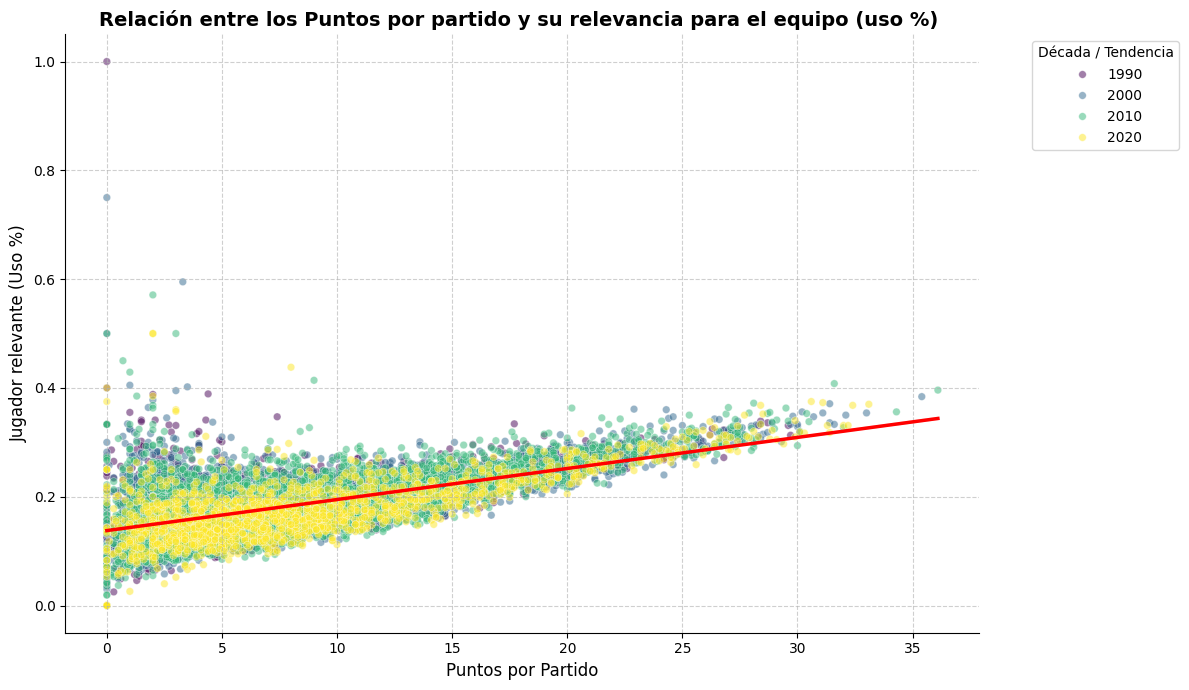

In [88]:
# Configuramos el gráfico de dispersión y la línea de tendencia
plt.figure(figsize=(12, 7))
# Gráfico de puntos diferenciados por década
sns.scatterplot(
    data=df,
    x="puntos",
    y="uso_pct",
    hue="decada",
    palette="viridis",
    alpha=0.5,
    s=30,
)
# Línea de tendencia general (regresión lineal)
sns.regplot(
    data=df,
    x="puntos",
    y="uso_pct",
    scatter=False,
    color="red",
    line_kws={"linewidth": 2.5, "label": "Tendencia General"},
)
sns.despine()
plt.title(
   "Relación entre los Puntos por partido y su relevancia para el equipo (uso %) ",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Puntos por Partido", fontsize=12)
plt.ylabel("Jugador relevante (Uso %)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

# Leyenda ordenada fuera del gráfico
plt.legend(
    title="Década / Tendencia",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    fontsize=10,
)
plt.tight_layout()
plt.show()

Vemos una correlacion general de 0.64% que paso de 0.53% en la decada del 90 a un 0.70% en la decada 2010-2020, esto idica que a lo largo de los años un potencial anotador mas elevado significa mayor relevancia  para el equipo.

Se observa que el grafico tiene una forma de "cono" que muestra que en promedio, mientras mas puntos por partido tiene un jugador mas relevancia ofensiva tiene en el equipo.

En la zona de 0 a 5 puntos por partido (izquierda), la dispersión en el eje Y es grande : hay desde jugadores con un uso bajísimo (cerca de 0) hasta casos atípicos (outliers) con un uso alto o medio pero que anotan muy poco.

Jugadores que consumen muchas posesiones y anotan poco o jugadores que meten muchos puntos en pocos minutos.  

A medida que nos movemos hacia la derecha (llegando a 20 puntos por partido), la nube de puntos se va acorotando cada vez mas y se va viviendo mas predecible: todos los grandes anotadores se concentran obligatoriamente en un rango de uso alto (entre 0.20 y 0.40).

condicion de necesidad: El sistema ofensivo del equipo depende mucho de la estrella de su equipo, (no existen anotadores de 30 puntos por partido con un uso del 0.10. Para anotar mucho, el sistema del equipo tiene que pasar por las manos de ese jugador.



In [89]:
# Agrupamos por edad y calculamos el promedio de puntos
puntos_por_edad = df.groupby("edad")["puntos"].mean().reset_index()

# Encontramos la edad exacta del 'prime' (el mayor promedio de puntos)
prime_row = puntos_por_edad.loc[puntos_por_edad["puntos"].idxmax()]
print(f""" El 'prime' anotador es a los {int(prime_row['edad'])} añoscon un promedio de {prime_row['puntos']:.2f} puntos.
      \n Llama la atención que la media de edades, sin embargo, es: {df['edad'].mean()}, y su mediana: {df['edad'].median()}.
      \n Esto nos podria llevar a pensar que en busqueda de 'el nuevo Messi' los equipos dejar ir antes de tiempo a los jugadores
      \n Tambien podríamos pensar que el 'prime' esta siendo movido por las 'super-estrellas'""")

 El 'prime' anotador es a los 28 añoscon un promedio de 9.32 puntos.
      
 Llama la atención que la media de edades, sin embargo, es: 27.045312986608533, y su mediana: 26.0.
      
 Esto nos podria llevar a pensar que en busqueda de 'el nuevo Messi' los equipos dejar ir antes de tiempo a los jugadores
      
 Tambien podríamos pensar que el 'prime' esta siendo movido por las 'super-estrellas'


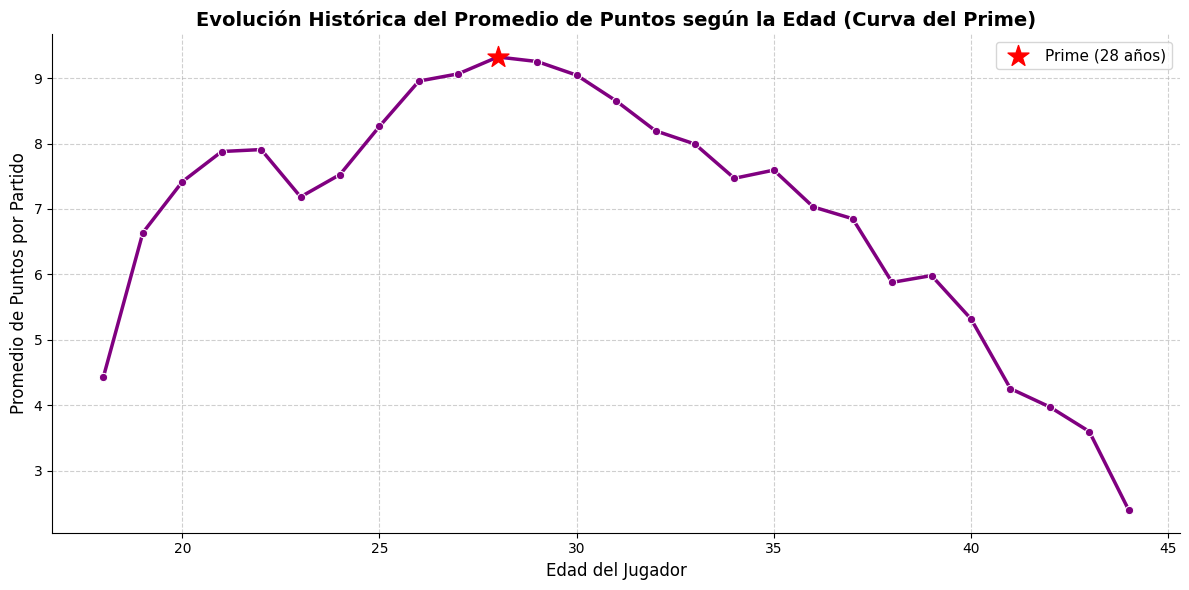

In [90]:
# Gráfico de la curva de rendimiento por edad
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=puntos_por_edad,
    x="edad",
    y="puntos",
    marker="o",
    linewidth=2.5,
    color="purple",
)
plt.scatter(
    prime_row["edad"],
    prime_row["puntos"],
    color="red",
    s=250,
    zorder=5,
    marker="*",
    label=f"Prime ({int(prime_row['edad'])} años)",
)
sns.despine()
plt.title(
    "Evolución Histórica del Promedio de Puntos según la Edad (Curva del Prime)",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Edad del Jugador", fontsize=12)
plt.ylabel("Promedio de Puntos por Partido", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

#Clasificación

In [91]:
# Creamos la variable objetivo (Target): 'es_estrella'
# Definimos estrella (1) si promedia más de 20 puntos O tiene un uso_pct mayor a 0.28. Caso contrario, promedio (0).
df["es_estrella"] = (
    (df["puntos"] > 20) | (df["uso_pct"] > 0.28)
).astype(int)
print("Distribución de clases:")
print(df["es_estrella"].value_counts(normalize=True) * 100)

Distribución de clases:
es_estrella
0    93.02398
1     6.97602
Name: proportion, dtype: float64


etiquetamos a los jugadores como estrellas (1) usando una regla sobre su temporada: si puntos > 20 o uso_pct > 0.28.

In [92]:
# las variables predictoras (X)
features = [
    "edad",
    "altura",
    "peso",
    "rebotes",
    "asistencias",
    "influencia_neta",
    "rebotes_ofs_pct",
    "rebotes_def_pct",
    "aciertos_pct",
    "asistencias_pct",
    "numero_draft",
]
# Limpiamos posibles nulos en 'numero_draft' (ej: undrafted pasan a un valor numérico alto o 0, o imputamos)
# 60 asume posición fuera de los picks habituales o rellenamos
df["numero_draft"] = df["numero_draft"].fillna(
    60)
X = df[features]
y = df["es_estrella"]


In [93]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Se realizo un pipeline de machine learning epara predecir si un jugador de la NBA alcanzará estatus de "Estrella" (Clase 1) o se mantendrá como un jugador "Promedio" (Clase 0). Se excluye los puntos y el uso porcentual, forzamos al algoritmo a buscar patrones estructurales en función de sus métricas físicas, de eficiencia y de desempeño en cancha a lo largo de cada temporada evitando el data leakage

In [94]:
# Entrenamos un Árbol de Decisión
clf = DecisionTreeClassifier(
    max_depth=4, class_weight="balanced", random_state=42
)
clf.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=4, random_state=42)

lass_weight = "balanced": Asignó un peso mayor a la clase minoritaria (estrellas) para obligar al árbol a prestarle atención a ese 7% de los datos, contrarrestando el sesgo natural hacia la clase mayoritaria.

 El umbral óptimo es: 0.91
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      2390
           1       0.45      0.58      0.50       179

    accuracy                           0.92      2569
   macro avg       0.71      0.76      0.73      2569
weighted avg       0.93      0.92      0.93      2569

Matriz de Confusión:


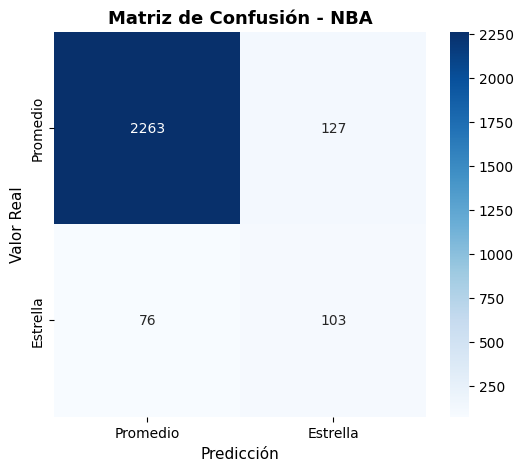

In [95]:
# Obtenemos las probabilidades de clase para el conjunto de prueba usando el árbol de decisión
y_probs = clf.predict_proba(X_test)[:, 1]

# Calculamos precision, recall y umbrales
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

# Buscamos el umbral que maximice el F1-score (el balance entre precisión y recall)
f1_scores = 2*(precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = f1_scores.argmax()
best_threshold = thresholds[best_idx]

print(f" El umbral óptimo es: {best_threshold:.2f}")

# Evaluamos con este umbral óptimo
y_pred_optimo = (y_probs >= best_threshold).astype(int)
print(classification_report(y_test, y_pred_optimo))

#  Matriz de Confusión
print("Matriz de Confusión:")
cm = confusion_matrix(
    y_test, y_pred_optimo)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Promedio", "Estrella"],
    yticklabels=["Promedio", "Estrella"],
)
plt.xlabel("Predicción", fontsize=11)
plt.ylabel("Valor Real", fontsize=11)
plt.title(
    "Matriz de Confusión - NBA", fontsize=13, weight="bold"
    )
plt.show()

Umbral Óptimo (0.91): El modelo ajustó el umbral de decisión a un valor muy alto (0.91). Esto significa que el arbol de Decisión exige una probabilidad superior al 91% para clasificar a un jugador como "Estrella" (1), priorizando la cautela para evitar falsos positivos.

Accuracy (0.92): A primera vista parece muy alto, pero en problemas desbalanceados (donde el 93% son jugadores promedio), el accuracy es engañoso: está inflado por la enorme cantidad de aciertos en la clase mayoritaria (jugadores promedio).

**CLASE CERO 0 (Jugadores promedio)**

Precision (0.97): Cuando el modelo predice que un jugador es promedio, acierta el 97% de las veces.

Recall (0.95): De todos los jugadores que realmente eran promedio, el modelo logró detectar al 95% (2,263 de 2,390).

**CLASE 1 (Jugadores estrella)**

Precision (0.45): De cada 100 jugadores que el modelo predijo como "Estrella",  45 eran verdaderamente estrellas, mientras que los otros 55 fueron falsos positivos. Este es el principal problema para los equipos en terminos de costo economico (jugadores que van a ser contratados como estrellas cuando no lo son) y costo en terminos de rendimiento, dado que los equipos de la NBA dependen mucho de sus jugadores estrellas, se les va a otorgar un rol dentro del equipo que no van a poder sostener en el tiempo.

Recall (0.58): De las 179 estrellas reales que existían en el conjunto de prueba, el árbol logró tomar al 58% (103 jugadores), dejando escapar al 42% restante (76 estrellas no detectadas).

F1-Score (0.50): Al ser la media armónica entre precisión y recall, refleja que el modelo sufre un trade-off importante al intentar cazar a la clase minoritaria con este algoritmo individual.

**MATRIZ CONFUSION**

Desglosando los 2,569 casos evaluados:

Verdaderos negativos (2,263): Jugadores promedio correctamente identificados. Es lo que sostiene el accuracy global.

Falsos positivos (127): Jugadores promedio a los que el modelo catalogó erróneamente como "Estrellas"

Falsos negativos (76): Estrellas reales que el modelo pasó por alto y clasificó como "promedio". En términos de captación de talento, este es el peor error (perderse a un talento de élite).

Verdaderos positivos (103): Estrellas auténticas captadas exitosamente.

A pesar de haber optimizado el umbral de decisión a 0.91 y usado pesos balanceados, el árbol de decisión individual muestra limitaciones claras:

un recall del 58% para las estrellas. Esto significa que casi de cada dos estrellas reales, el árbol se pierde a una.

Un 45% de precisión en la clase estrella, el modelo genera un volumen importante de ruido (falsas estrellas)




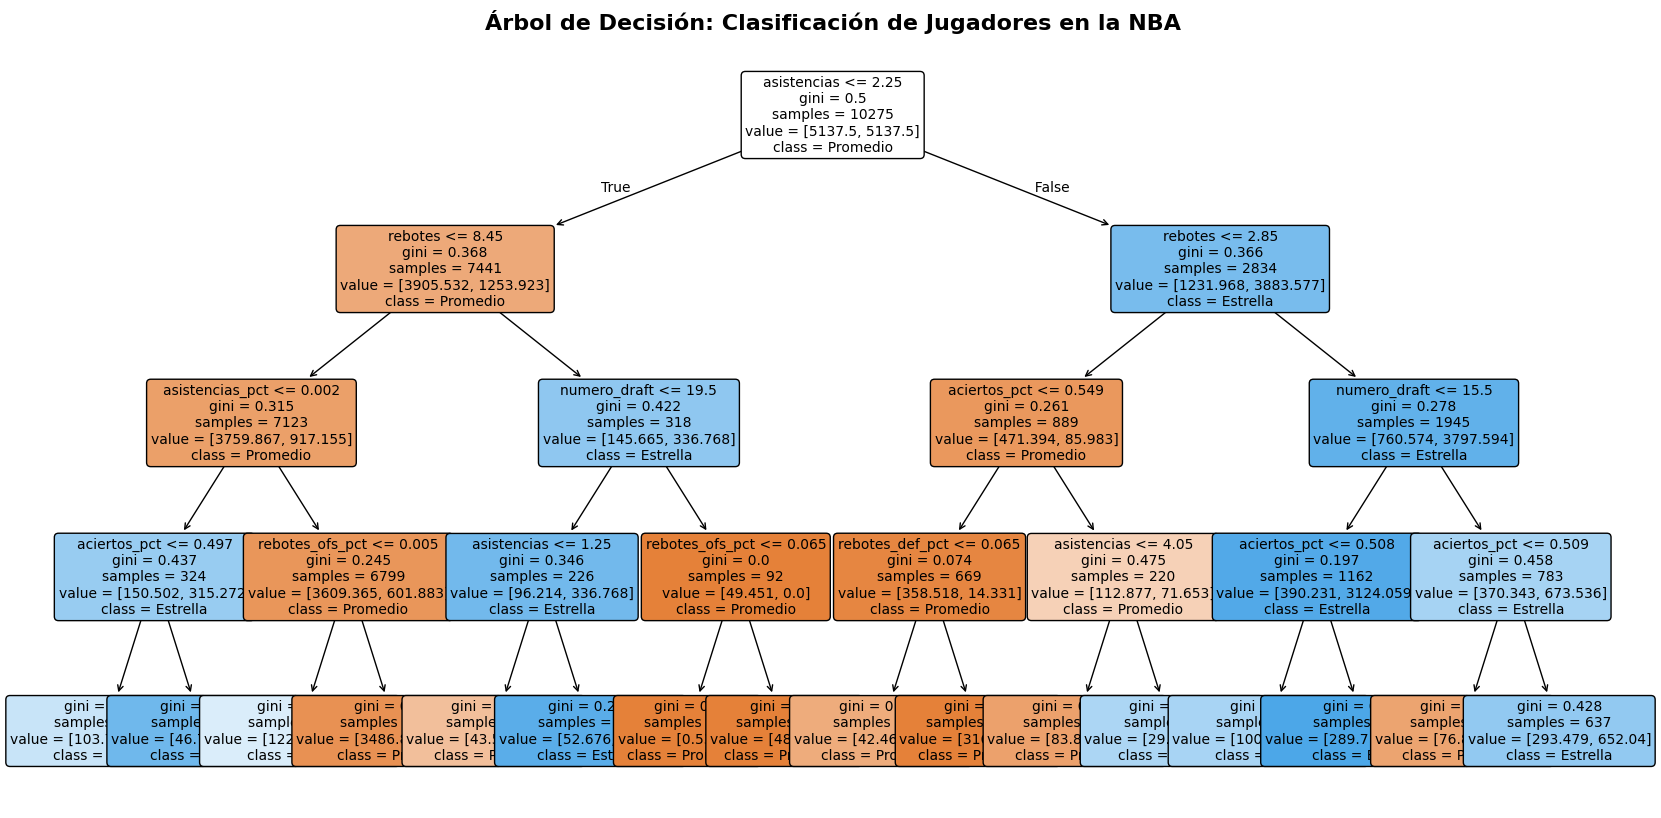

In [96]:
# Visualizamos la estructura de decisiones del árbol
plt.figure(figsize=(20, 10))
plot_tree(
    clf,
    feature_names=features,
    class_names=["Promedio", "Estrella"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title(
    "Árbol de Decisión: Clasificación de Jugadores en la NBA",
    fontsize=16,
    weight="bold",
)
plt.show()

En la estructura jerárquica del árbol de decisión, los nodos se diferencian según su clasificación: los nodos azules muestran la clase "estrella", y los nodos naranjas muestran la calse Promedio. Metodológicamente, el modelo prioriza en su bifurcación raíz la capacidad de creación de juego a través de las asistencias (estableciendo un umbral inicial de por lo menos 2.25), y va refinando con las sucesivas ramas mas profundas combinando métricas complementarias de rendimiento y origen, tales como el número de draft, la eficiencia de tiro (aciertos_pct) y el volumen de rebotes.

Para mejorar la perforance de la prediccion se corrio un Random Forest

El umbral óptimo para Random Forest es: 0.77
Reporte de Clasificación (Random Forest Optimizado)
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      2390
           1       0.60      0.55      0.58       179

    accuracy                           0.94      2569
   macro avg       0.79      0.76      0.77      2569
weighted avg       0.94      0.94      0.94      2569



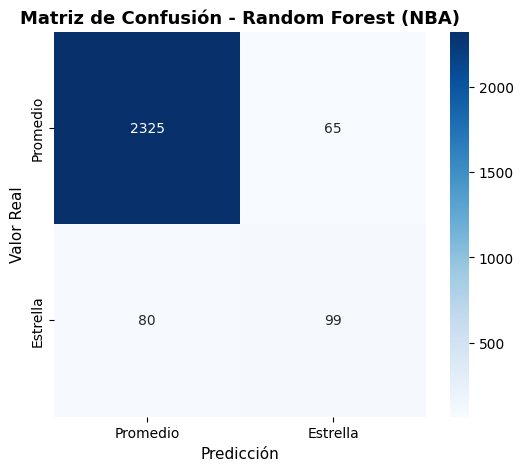

In [97]:
# Instanciamos y entrenamos el Random Forest
# Usamos n_estimators=100 (100 árboles) y class_weight='balanced' para manejar el desbalance
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight='balanced',
    random_state=42)
rf.fit(X_train, y_train)

# Obtenemos las probabilidades de la clase 1 (Estrella)
y_probs_rf = rf.predict_proba(X_test)[:, 1]

# precision, recall y umbrales para el Random Forest
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs_rf)

# Buscamos el umbral que maximiza el F1-score (balance óptimo)
f1_scores = (2 * (precisions * recalls)) / (precisions + recalls + 1e-10)
best_idx = f1_scores.argmax()
best_threshold = thresholds[best_idx]

print(f"El umbral óptimo para Random Forest es: {best_threshold:.2f}")

# Evaluamos el modelo utilizando este umbral óptimo
y_pred_optimo_rf = (y_probs_rf >= best_threshold).astype(int)
print("Reporte de Clasificación (Random Forest Optimizado)")
print(classification_report(y_test, y_pred_optimo_rf))

# Visualizamos la Matriz (usamos y_pred_optimo_rf)
cm = confusion_matrix(y_test, y_pred_optimo_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Promedio', 'Estrella'],
    yticklabels=['Promedio', 'Estrella']
)
plt.xlabel('Predicción', fontsize=11)
plt.ylabel('Valor Real', fontsize=11)
plt.title('Matriz de Confusión - Random Forest (NBA)', fontsize=13, weight='bold')
plt.show()

Umbral Óptimo (0.77): El modelo fijó un punto de corte equilibrado.

Accuracy(0.94 / 94%): Muestra una mejora respecto al modelo base.

**CLASE 0 (Jugadores promedio)**

Precision (0.97).

Recall (0.97): El modelo logra captar 97% de los verdaderos promedio, unos 62 jugadores mas que el anterior.


**Clase 1 (Jugadores estrellas)**

Precision (0.60): Una mejora notable respecto al 45% del árbol individual. Significa que de cada 10 jugadores que el Random Forest señala como "Estrella", 6 son verdaderamente estrella. Logro reducir el costo economico y de rendimiento para un equipo.

Recall (0.55): De las 179, el modelo detectó al 55% (99 jugadores). Si bien se le escapan 80 jugadores (falsos negativos), prioriza la calidad del acierto sobre la cantidad masiva.

F1-Score (0.58): Sube de forma importante frente al 0.50 anterior, evidenciando un balance armónico superior entre precisión y cobertura.

**MATRIZ CONFUSIÓN**

Desglosando los 2,569 casos evaluados:

Verdaderos negativos (2,325): Jugadores promedio correctamente catalogados.

Falsos positivos (65) Se redujeron casi a la mitad en comparación con los 127 del árbol de decisión, optimizando los recursos del cuerpo técnico al no ilusionarse con perfiles erróneos.

Falsos negativos (80): Estrellas reales omitidas. Aunque hay un leve incremento numérico de 4 casos frente al árbol anterior, este es el costo pagado para limpiar el ruido y duplicar la confiabilidad de las alertas.

El Random Forest demostró ser un mejor modelo. Al combinar múltiples árboles y suavizar las fronteras de decisión rígidas, el modelo eliminó la alta inestabilidad del árbol base.




Umbral óptimo: 0.77 (F1-score: 0.5773)


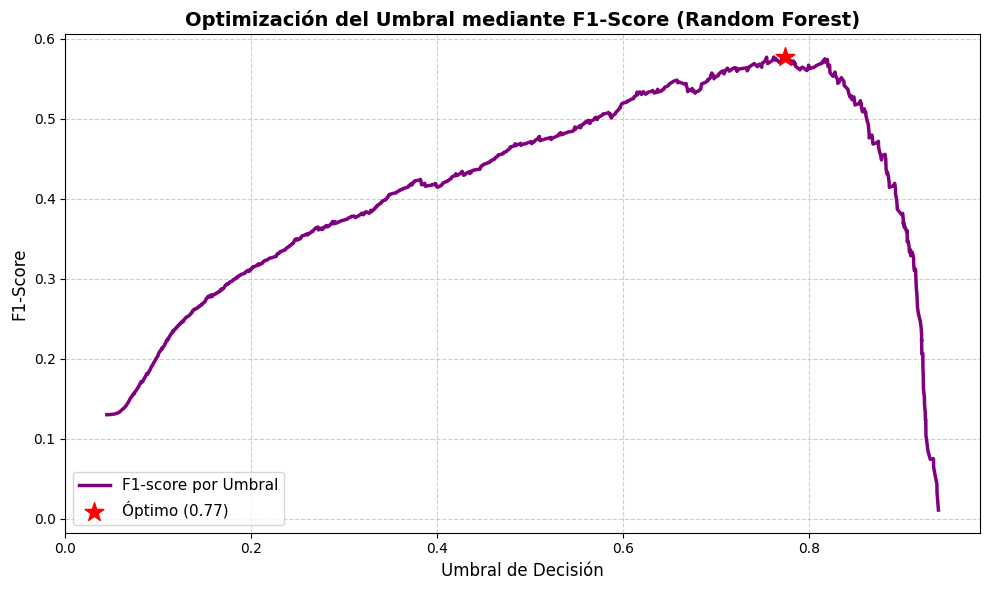

In [98]:
f1_scores = (2 * (precisions[:-1] * recalls[:-1])) / (
    precisions[:-1] + recalls[:-1] + 1e-10
)

# umbral que maximiza el F1-score
best_idx = f1_scores.argmax()
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Umbral óptimo: {best_threshold:.2f} (F1-score: {best_f1:.4f})")

# gráfico de la curva del F1-score
plt.figure(figsize=(10, 6))
plt.plot(
    thresholds,
    f1_scores,
    color="purple",
    linewidth=2.5,
    label="F1-score por Umbral",
)
# punto óptimo en el gráfico
plt.scatter(
    best_threshold,
    best_f1,
    color="red",
    s=200,
    zorder=5,
    marker="*",
    label=f"Óptimo ({best_threshold:.2f})",
)
plt.title(
    "Optimización del Umbral mediante F1-Score (Random Forest)",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Umbral de Decisión", fontsize=12)
plt.ylabel("F1-Score", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11, loc="lower left")
plt.tight_layout()
plt.show()

#Clustering

Nos interesa ver si hay una diferencia historica entre los equipos. Hay franquicias que constantemente desempeñan bien durante la temporada de la NBA, llegando regularmente a las play-off. Mientas que otras son mas consistentes en su incapacidad de pasar a esa etapa del tornoe.

Nos preguntamos si un algortmo de cluster es capaz de dividir a los equipos de acuerdo a ese critero.

In [99]:
#Lo primero que hacemos es unificar los nombres de los equipos que, a lo largo del tiempo cambiaron su nombre
renombre_equipos = {
    # Washington Bullets -> Washington Wizards
    'WSB': 'WAS',    'WAS': 'WAS',

    # Vancouver Grizzlies -> Memphis Grizzlies
    'VAN': 'MEM',    'MEM': 'MEM',

    # Seattle SuperSonics -> Oklahoma City Thunder
    'SEA': 'OKC',    'OKC': 'OKC',

    # New Jersey Nets -> Brooklyn Nets
    'NJN': 'BKN',    'BKN': 'BKN',

    # New Orleans Hornets -> New Orleans Pelicans
    'NOH': 'NOP',    'NOK': 'NOP',    'NOP': 'NOP',

    # Charlotte Bobcats -> Charlotte Hornets
    'CHA': 'CHA',    'CHH': 'CHA',

    # Resto de equipos sin cambios de franquicia
    'HOU': 'HOU',    'LAL': 'LAL',    'DEN': 'DEN',    'ORL': 'ORL',    'MIL': 'MIL',    'DET': 'DET',    'POR': 'POR',    'DAL': 'DAL',    'UTA': 'UTA',    'BOS': 'BOS',
    'IND': 'IND',    'SAS': 'SAS',    'MIA': 'MIA',    'ATL': 'ATL',    'LAC': 'LAC',    'GSW': 'GSW',    'PHI': 'PHI',    'NYK': 'NYK',    'TOR': 'TOR',    'PHX': 'PHX',
    'MIN': 'MIN',    'CHI': 'CHI',    'SAC': 'SAC',    'CLE': 'CLE'
}

In [100]:
print(f"Cuartiles de cantidad de partidos por temporada de los jugadores: \n{df["partidos"].describe().loc[["25%","50%","75%","max"]]}")

Cuartiles de cantidad de partidos por temporada de los jugadores: 
25%    31.0
50%    57.0
75%    73.0
max    85.0
Name: partidos, dtype: float64


In [101]:
df_clst = df.copy()
df_clst['equipo'] = df_clst['equipo'].map(renombre_equipos)
df_clst = df_clst[df_clst["partidos"] >= 31].copy()

Consideraremos para el cluster solamente los jugadores que tienen mas de 31 partidos.

El criterio por el cual adoptamos este corte es que los jugadores que estuvieron en menos de 31 partidos, a veces un par de minutos por partido, bajan las medias de los equipos buenos. Logran el efecto de igualar a todos los equipos cuando lo que queremos es que se diferencien bien para que el algoritmo pueda separalos.

Como venimos viendo a lo largo del analizis el baloncesto es un deporte en donde los jugadores estrella tienen una alta capacidad de influir en el resultado de un partido; los jugadores con poco tiempo en cancha (segundos suplentes) evaporan la diferencia que las superestrellas generan en los equipos.

Recordemos durante el AED, en el describe del df,  como las métricas de desempeño eran negativas. Como vimos en la clasificacion dados 100 jugadores solamente 6 son estrellas. Si no resttringimos el df para este analisis el resto de los jugadores harán que todos los equipos terminen iguales en la media de los 94 jugadores 'no estrella'.

In [102]:
#Definimos la funcion por la cual vamos a calcular el desempeño de un equipo en una temporada
def calcular_metricas_equipo(g):
  cantPartidos = g["partidos"]

  #Promedio de influencia neta ponderada por la cantidad de partidos jugados
  influencia_neta_ponderada = np.average(g["influencia_neta"], weights=cantPartidos)

  #Promedio de porcentaje de aciertos ponderada por la cantidad de partidos jugados
  aciertos_pct_ponderado = np.average(g["aciertos_pct"], weights=cantPartidos)

  #Media de puntos de los dos jugadores con mas puntos.
  puntos_top_anotadores = g["puntos"].nlargest(2).mean()

  return pd.Series({
      "influencia neta ponderada": influencia_neta_ponderada,
      "aciertos pct ponderado": aciertos_pct_ponderado,
      "puntos top anotadores": puntos_top_anotadores
  })

eq_temp = df_clst.groupby(["equipo", "temporada"]).apply(calcular_metricas_equipo,include_groups=False).reset_index()
eq_temp.head()

,equipo,temporada,influencia neta ponderada,aciertos pct ponderado,puntos top anotadores
0,ATL,1996,5.974814,0.537863,19.10
1,ATL,1997,2.844648,0.527863,17.20
2,ATL,1998,1.885553,0.486323,16.00
3,ATL,1999,-6.125472,0.505434,18.00
4,ATL,2000,-5.529620,0.498797,16.05


Por equipo, por temporada calculamos tres métricas. Influencia neta ponderada, aciertos pct ponderado, y puntos top anotadores. Asi obtenemos un perfil del equipo en un año determinado.

Lo hacemos por temporada y no por decada, o todo el df, porque el tiempo aplana los resultados. Un equipo que es consistentemente bueno tiene momentos en los que no lo es; y un equipo malo tiene años en los que es bueno.

La NBA tiene aparte mecanismos para favorecer a los equipos menos exitosos y desfavorecer a los mas exitosos, como el sistema de draft.

Por eso es importante mantener los datos por temporada y no unificarlos.

In [103]:
#normalizamos
cols_metrica = ["influencia neta ponderada","aciertos pct ponderado","puntos top anotadores"]

for col in cols_metrica:
    eq_temp[col] = eq_temp.groupby("temporada")[col].transform(
        lambda x: (x - x.mean()) / (x.std() + 1e-6)
    )

In [104]:
eq_temp.head()

,equipo,temporada,influencia neta ponderada,aciertos pct ponderado,puntos top anotadores
0,ATL,1996,1.112075,0.505267,-0.042167
1,ATL,1997,0.578539,0.508191,-0.480042
2,ATL,1998,0.414365,-1.160212,-0.600922
3,ATL,1999,-1.199714,-0.652023,-0.483589
4,ATL,2000,-1.075580,-0.761084,-1.201635


In [105]:
#Calculamos metricas historicas de los equipo

perfil_equipo = eq_temp.groupby("equipo").agg(
            influencia_neta_promedio=("influencia neta ponderada", "mean"), #influencia neta promedio
            influencia_neta_techo=("influencia neta ponderada", lambda x: np.percentile(x, 80)), # Techo en años buenos
            porcentaje_años_buenos_influencia=("influencia neta ponderada", lambda x: (x > 0.5).mean()), # % temporadas destacadas
            consistencia_influencia=("influencia neta ponderada", "std"),   # Estabilidad a lo largo de los años

            aciertos_pct_promedio=("aciertos pct ponderado", "mean"),
            porcentaje_años_buenos_aciertos=("aciertos pct ponderado", lambda x: (x > 0.5).mean()),
            consistencia_aciertos=("aciertos pct ponderado", "std"),

            puntos_top_promedio=("puntos top anotadores", "mean"),
            puntos_top_techo=("puntos top anotadores", lambda x: np.percentile(x, 80)),
            porcentaje_años_buenos_puntos_top=("puntos top anotadores", lambda x: (x > 0.5).mean()),
                ).reset_index()

In [106]:
perfil_equipo.head()

,equipo,influencia_neta_promedio,influencia_neta_techo,porcentaje_años_buenos_influencia,consistencia_influencia,aciertos_pct_promedio,porcentaje_años_buenos_aciertos,consistencia_aciertos,puntos_top_promedio,puntos_top_techo,porcentaje_años_buenos_puntos_top
0,ATL,-0.300498,0.554715,0.222222,0.908692,-0.012660,0.333333,0.765667,-0.328411,0.167090,0.037037
1,BKN,-0.334869,0.136548,0.111111,0.781745,-0.396636,0.074074,0.938423,-0.037632,0.624029,0.333333
2,BOS,0.359918,0.977427,0.444444,0.891834,0.285694,0.407407,0.896874,0.196187,1.075339,0.296296
3,CHA,-0.439513,0.313951,0.120000,0.895726,-0.476467,0.240000,1.041659,-0.574018,-0.065652,0.040000
4,CHI,-0.208947,0.703291,0.259259,1.250903,-0.794985,0.074074,0.872314,-0.141443,0.395779,0.185185


In [107]:
#Dropeamos la columna equipos, escalamos y aplicamos el clustering KMean con dos clusters
X = perfil_equipo.drop(columns=["equipo"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
perfil_equipo["cluster"] = kmeans_final.fit_predict(X_scaled)

In [108]:
perfil_equipo.sort_values(by="cluster", ascending=False, inplace=True)
perfil_equipo.head()

,equipo,influencia_neta_promedio,influencia_neta_techo,porcentaje_años_buenos_influencia,consistencia_influencia,aciertos_pct_promedio,porcentaje_años_buenos_aciertos,consistencia_aciertos,puntos_top_promedio,puntos_top_techo,porcentaje_años_buenos_puntos_top,cluster
2,BOS,0.359918,0.977427,0.444444,0.891834,0.285694,0.407407,0.896874,0.196187,1.075339,0.296296,1
6,DAL,0.445418,1.058537,0.555556,0.812958,0.514378,0.518519,0.915534,0.252023,0.817413,0.481481,1
10,HOU,0.267557,1.127602,0.444444,0.972342,0.532461,0.444444,0.920493,0.413473,1.023986,0.555556,1
13,LAL,0.277575,1.235909,0.444444,0.986225,-0.074923,0.185185,0.877037,1.243885,1.964231,0.777778,1
9,GSW,-0.028103,1.103713,0.259259,1.184536,0.206223,0.518519,1.381830,0.345685,1.240887,0.481481,1


In [109]:
perfil_equipo['cluster'].value_counts()

,count
cluster,
0,20
1,10


KMeans nos separa los 30 equipos en dos grupos. Un grupo de 10 compuesto por los  'superequipos', y otro compuesto por los otros 20.

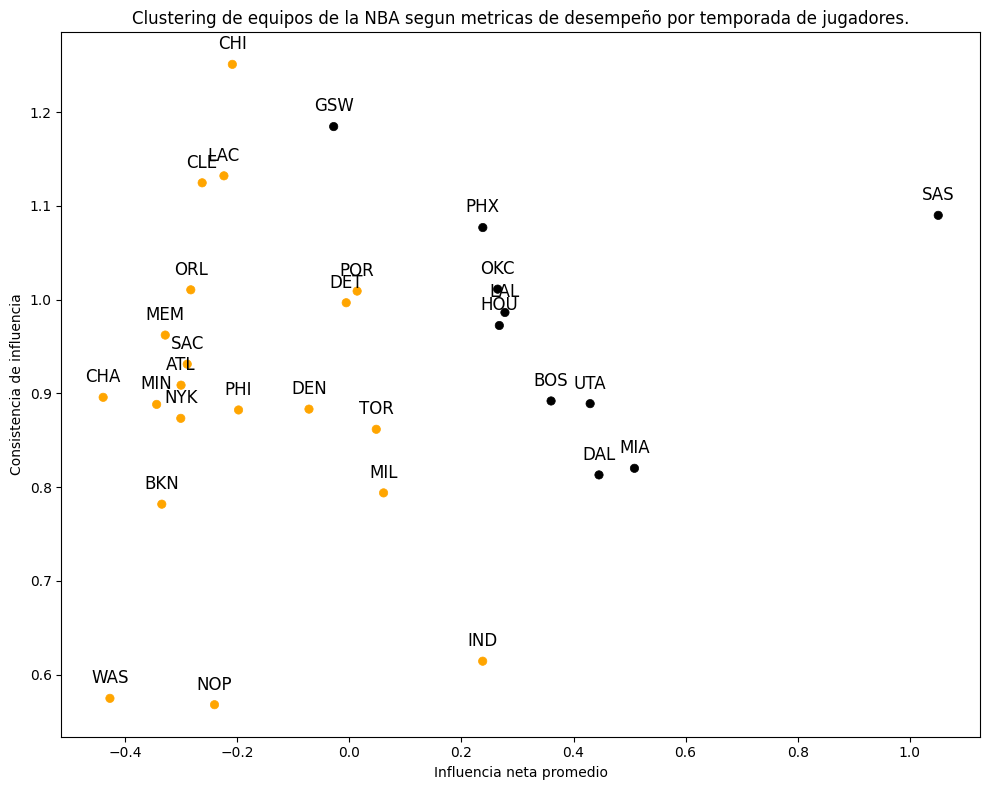

In [110]:
fig, ax = plt.subplots(figsize=(10, 8))
(
    so.Plot(perfil_equipo,x='influencia_neta_promedio', y='consistencia_influencia',color='cluster')
    .add(so.Dot(), legend=False)
    .scale(color={1:'black',0:'orange'})
    .add(so.Text(valign="bottom", offset=8, color="black"), text="equipo")
    .label(title='Clustering de equipos de la NBA segun metricas de desempeño por temporada de jugadores.',
           x='Influencia neta promedio',
           y='Consistencia de influencia')
).on(ax).plot()

plt.tight_layout()
plt.show()

Vemos una clara separación entre los equipos lo que nos lleva a pensar que el clustering esta brindando informacion interesante.

Por conocimiento de experto reconocemos que nos logro dividir exitosamente a los equipos historicamente ganadores del resto. Equipos conocidos como los Lakers (LAL) y los Celtics (BOS) se encuentran entre los equipos historicamente exitosos.

Para tener una comprobación mas 'empirica' traemos la información de las cantidad de veces que cada equipo paso a las play oof durante el periodo 1996-2022.

In [111]:
pd.DataFrame({
    "franquicia": [
        "Atlanta Hawks",        "Boston Celtics",        "Brooklyn Nets",        "Charlotte Hornets",        "Chicago Bulls",        "Cleveland Cavaliers",        "Dallas Mavericks",        "Denver Nuggets",
        "Detroit Pistons",        "Golden State Warriors",        "Houston Rockets",        "Indiana Pacers",        "Los Angeles Clippers",        "Los Angeles Lakers",        "Memphis Grizzlies",        "Miami Heat",
        "Milwaukee Bucks",        "Minnesota Timberwolves",        "New Orleans Pelicans",        "New York Knicks",        "Oklahoma City Thunder",        "Orlando Magic",        "Philadelphia 76ers",
        "Phoenix Suns",        "Portland Trail Blazers",        "Sacramento Kings",        "San Antonio Spurs",        "Toronto Raptors",        "Utah Jazz",        "Washington Wizards"    ],
    "playoffs": [
        13,19,14,8,12,12,  17,  16,  13,  10,  16,  18,  13,  19,  14,  20,  16,  14,  9,   12,  16,  14,  16,  15,  17,  9,   23,  13,  18,  10
    ]}).sort_values('playoffs',ascending=False).reset_index()

,index,franquicia,playoffs
0,26,San Antonio Spurs,23
1,15,Miami Heat,20
2,1,Boston Celtics,19
3,13,Los Angeles Lakers,19
4,11,Indiana Pacers,18
5,28,Utah Jazz,18
6,24,Portland Trail Blazers,17
7,6,Dallas Mavericks,17
8,16,Milwaukee Bucks,16
9,22,Philadelphia 76ers,16


Vemos que los equipos que mas veces pasaron a los playoffs son los mismos equipos que el clustering separa.

El mas llamativo es que cataloga al equipo Indiana pacers (IND) con los equipos no superestrellas a pesar de haber ser el quinto equipo que mas llego a las play off. Y que cataloga a los golden states warrior (GSW) como un superequipo a pesar de tener solo 10 playoffs. Sin embargo de esas 10 playoff los GSW ganaron 4, con lo que se puede ver que, sobre todo al final del periodo registrado en el data set, fueron un equipo dominante.

Recordamos que la base de datos no trata sobre playoff sino desempeño individual de jugadores. Puede haber pasaro que GSW tenga un exeletne desempeño individual de sus jugadores de mas de 31 partidos pero que no hayan logrado pasar a las playoff por diversas razones; y que IND quizas sin un desempeño sobresaliente de sus jugadores si lo haya logrado. Sea por habilidad de los entrenadores, porque su division era 'mas facil', o por otras razones.